In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, roc_curve)

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [4]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")   # 0 = malignant, 1 = benign

print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())
print("\nClass distribution:")
print(y.value_counts())
X.head()

Shape: (569, 30)
Missing values: 0

Class distribution:
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
# Feature ranges differ a lot - this matters for SVM
X.describe().T[["mean", "std", "min", "max"]].head(10)

,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


## Step 3: Train / Test Split and Feature Scaling
**SVM is distance based, so feature scaling is essential.** We fit the scaler only on the training data to avoid data leakage.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training set:", X_train_s.shape)
print("Testing set :", X_test_s.shape)

Training set: (455, 30)
Testing set : (114, 30)


In [7]:
def evaluate(model, Xtr, Xte, name):
    """Train a model, return its metrics as a dict."""
    start = time.time()
    model.fit(Xtr, y_train)
    train_time = time.time() - start

    pred = model.predict(Xte)
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(Xte)[:, 1]
    else:
        score = model.decision_function(Xte)

    return {
        "Model": name,
        "Train Acc": model.score(Xtr, y_train),
        "Test Acc": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
        "Train Time (s)": train_time,
    }, model, pred, score

In [8]:
svm_linear = SVC(kernel="linear", C=1.0, random_state=42)
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)

res_lin, svm_linear, pred_lin, score_lin = evaluate(svm_linear, X_train_s, X_test_s, "SVM (Linear)")
res_rbf, svm_rbf, pred_rbf, score_rbf = evaluate(svm_rbf, X_train_s, X_test_s, "SVM (RBF)")

pd.DataFrame([res_lin, res_rbf]).set_index("Model").round(4)

,Train Acc,Test Acc,Precision,Recall,F1-score,ROC-AUC,Train Time (s)
Model,,,,,,,
SVM (Linear),0.9912,0.9737,0.9859,0.9722,0.9790,0.9964,0.0106
SVM (RBF),0.9824,0.9825,0.9861,0.9861,0.9861,0.9950,0.0093


In [9]:
print("SVM (RBF) - Classification Report")
print(classification_report(y_test, pred_rbf, target_names=data.target_names))
print("Support vectors per class:", svm_rbf.n_support_, "| total:", svm_rbf.n_support_.sum())

SVM (RBF) - Classification Report
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Support vectors per class: [51 46] | total: 97


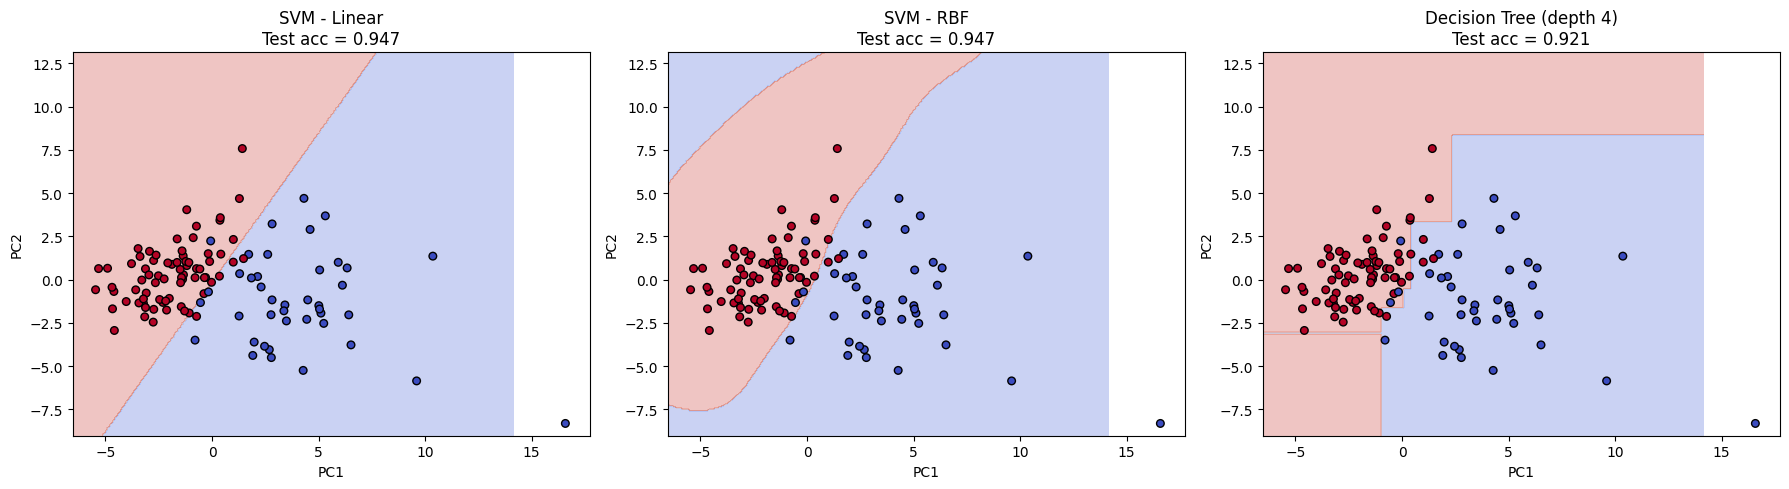

In [10]:
pca = PCA(n_components=2)
Xtr_2d = pca.fit_transform(X_train_s)
Xte_2d = pca.transform(X_test_s)

def plot_boundary(model, title, ax):
    model.fit(Xtr_2d, y_train)
    x_min, x_max = Xtr_2d[:, 0].min() - 1, Xtr_2d[:, 0].max() + 1
    y_min, y_max = Xtr_2d[:, 1].min() - 1, Xtr_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(Xte_2d[:, 0], Xte_2d[:, 1], c=y_test, cmap="coolwarm", edgecolor="k", s=30)
    ax.set_title(f"{title}\nTest acc = {model.score(Xte_2d, y_test):.3f}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_boundary(SVC(kernel="linear"), "SVM - Linear", axes[0])
plot_boundary(SVC(kernel="rbf"), "SVM - RBF", axes[1])
plot_boundary(DecisionTreeClassifier(max_depth=4, random_state=42), "Decision Tree (depth 4)", axes[2])
plt.tight_layout()
plt.show()

Note how SVM gives a smooth boundary, while the decision tree gives **axis-parallel (rectangular)** regions.

In [11]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.001, 0.01, 0.1],
    "kernel": ["rbf", "linear"],
}

grid_svm = GridSearchCV(SVC(probability=True, random_state=42), param_grid,
                        cv=5, scoring="accuracy", n_jobs=-1)
grid_svm.fit(X_train_s, y_train)

print("Best parameters :", grid_svm.best_params_)
print("Best CV accuracy:", round(grid_svm.best_score_, 4))

Best parameters : {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV accuracy: 0.9802


In [12]:
# Default decision tree
dt = DecisionTreeClassifier(random_state=42)

# Tuned decision tree
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"criterion": ["gini", "entropy"], "max_depth": [2, 3, 4, 5, 6, 8, None],
     "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4]},
    cv=5, scoring="accuracy", n_jobs=-1)
grid_dt.fit(X_train, y_train)
print("Best Decision Tree parameters:", grid_dt.best_params_)

# Random forest (ensemble of trees)
rf = RandomForestClassifier(n_estimators=100, random_state=42)

Best Decision Tree parameters: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [13]:
svm_best = SVC(probability=True, random_state=42, **grid_svm.best_params_)
dt_best = DecisionTreeClassifier(random_state=42, **grid_dt.best_params_)

runs = [
    (SVC(kernel="rbf", probability=True, random_state=42), "SVM (RBF, default)", "scaled"),
    (svm_best,                                             "SVM (tuned)",        "scaled"),
    (dt,                                                   "Decision Tree (default)", "raw"),
    (dt_best,                                              "Decision Tree (tuned)",   "raw"),
    (rf,                                                   "Random Forest",           "raw"),
]

results, fitted, preds, scores = [], {}, {}, {}
for model, name, kind in runs:
    Xtr, Xte = (X_train_s, X_test_s) if kind == "scaled" else (X_train.values, X_test.values)
    r, m, p, s = evaluate(model, Xtr, Xte, name)
    results.append(r); fitted[name] = m; preds[name] = p; scores[name] = s

comparison = pd.DataFrame(results).set_index("Model").round(4)
comparison

,Train Acc,Test Acc,Precision,Recall,F1-score,ROC-AUC,Train Time (s)
Model,,,,,,,
"SVM (RBF, default)",0.9824,0.9825,0.9861,0.9861,0.9861,0.9950,0.0484
SVM (tuned),0.9846,0.9825,0.9861,0.9861,0.9861,0.9937,0.0245
Decision Tree (default),1.0000,0.9123,0.9559,0.9028,0.9286,0.9157,0.0260
Decision Tree (tuned),0.9868,0.9386,0.9577,0.9444,0.9510,0.9342,0.0203
Random Forest,1.0000,0.9561,0.9589,0.9722,0.9655,0.9937,0.6139


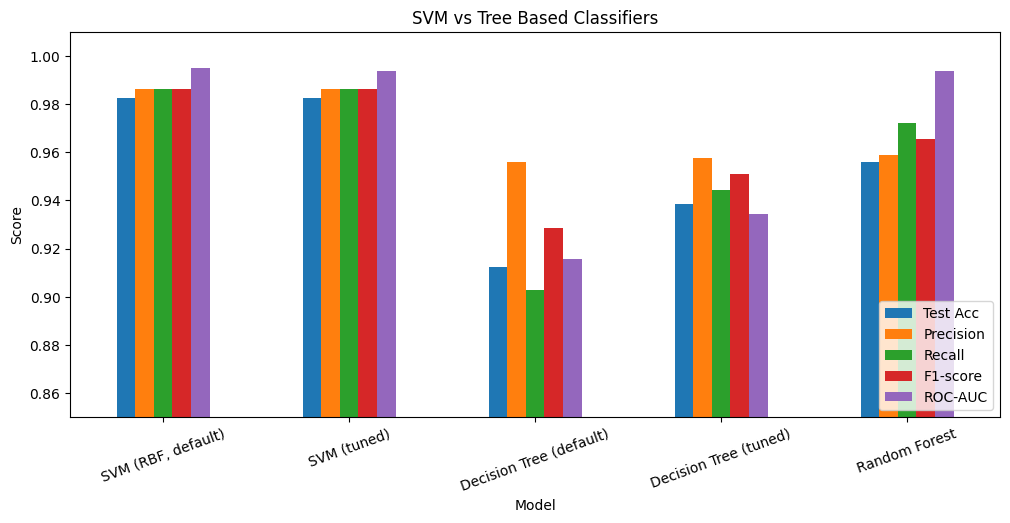

In [14]:
comparison[["Test Acc", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0.85, 1.01))
plt.title("SVM vs Tree Based Classifiers")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.show()

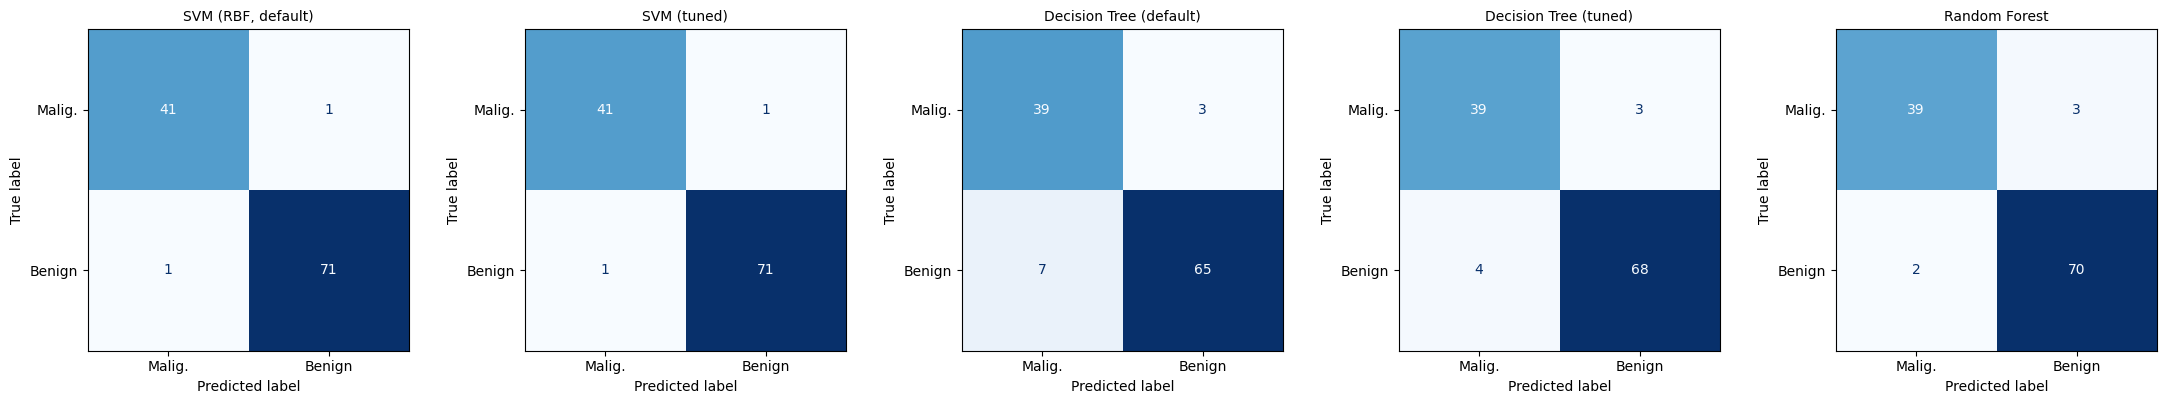

In [15]:
# Confusion matrices
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p),
                           display_labels=["Malig.", "Benign"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

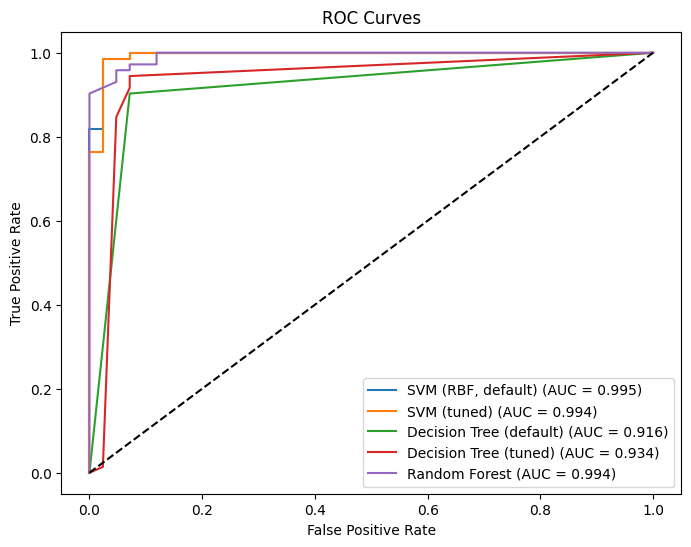

In [16]:
# ROC curves
plt.figure(figsize=(8, 6))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(loc="lower right")
plt.show()

SVM (tuned)               mean = 0.9737  std = 0.0055
Decision Tree (tuned)     mean = 0.9209  std = 0.0202
Random Forest             mean = 0.9561  std = 0.0228


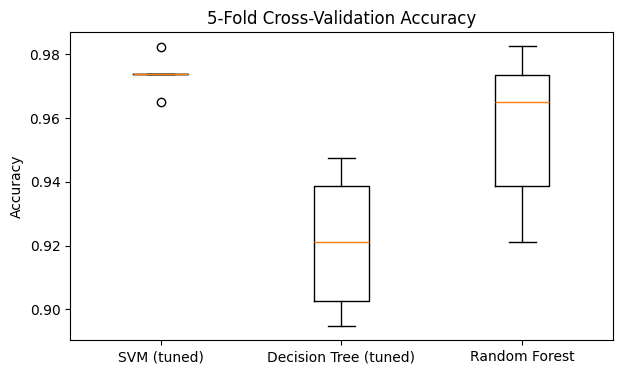

In [17]:
# 5-fold cross-validation for a more reliable comparison
# (SVM uses a pipeline so scaling happens inside each fold)
cv_models = {
    "SVM (tuned)": Pipeline([("scale", StandardScaler()),
                             ("svm", SVC(random_state=42, **grid_svm.best_params_))]),
    "Decision Tree (tuned)": dt_best,
    "Random Forest": rf,
}
cv_results = {}
for name, m in cv_models.items():
    sc = cross_val_score(m, X, y, cv=5)
    cv_results[name] = sc
    print(f"{name:<25} mean = {sc.mean():.4f}  std = {sc.std():.4f}")

plt.figure(figsize=(7, 4))
plt.boxplot(list(cv_results.values()))
plt.xticks(range(1, len(cv_results) + 1), list(cv_results.keys()))
plt.title("5-Fold Cross-Validation Accuracy")
plt.ylabel("Accuracy")
plt.show()

## Step 9: Effect of Feature Scaling
SVM is sensitive to feature scale, tree based models are not. Let's check.

In [18]:
svm_raw = SVC(kernel="rbf", random_state=42).fit(X_train, y_train)
svm_scaled = SVC(kernel="rbf", random_state=42).fit(X_train_s, y_train)
dt_raw = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
dt_scaled = DecisionTreeClassifier(random_state=42).fit(X_train_s, y_train)

scale_df = pd.DataFrame({
    "Without scaling": [svm_raw.score(X_test, y_test), dt_raw.score(X_test, y_test)],
    "With scaling":    [svm_scaled.score(X_test_s, y_test), dt_scaled.score(X_test_s, y_test)],
}, index=["SVM (RBF)", "Decision Tree"]).round(4)
scale_df

,Without scaling,With scaling
SVM (RBF),0.9298,0.9825
Decision Tree,0.9123,0.9123
